In [ ]:
# ==========================================================
#                   Universidad Franz Tamayo
# ----------------------------------------------------------
#                        MINERIA DE DATOS
# ----------------------------------------------------------
#        Enrique Alejandro Laurel Cossio, Octubre 2026
# ==========================================================
#  Clase: K-Means Clustering - Cuantización y Restauración de Imágenes
# ==========================================================

# 🎨 K-Means Clustering: Cuantización y Restauración de Imágenes
## Universidad Franz Tamayo — Minería de Datos
### Docente: Enrique Alejandro Laurel Cossio | 2026

---

## 🎯 Objetivos de la Clase

Al finalizar esta clase, el estudiante será capaz de:

1. ✅ **Entender** cómo K-Means puede aplicarse al dominio de procesamiento de imágenes
2. ✅ **Comprender** el concepto de cuantización de color con clustering
3. ✅ **Implementar** un pipeline de mejora y restauración de imágenes deterioradas usando K-Means
4. ✅ **Visualizar** el efecto del número de clusters K en la calidad de la imagen resultante
5. ✅ **Evaluar** la diferencia entre la imagen original, deteriorada y restaurada

---

> 💡 **Contexto**: Tomaremos una imagen que simula estar **deteriorada o envejecida** (con ruido, colores apagados, manchas) y usaremos K-Means para **reducir el espacio de colores** y reconstruir una versión más limpia y vibrante.

---
# 📚 PARTE 1: Marco Teórico

---

## 🖼️ ¿Cómo se representa una imagen digitalmente?

Una imagen digital es una **matriz de píxeles**. Cada píxel tiene un color representado en el espacio **RGB**:

| Canal | Descripción | Rango |
|---|---|---|
| **R** | Rojo (Red) | 0 – 255 |
| **G** | Verde (Green) | 0 – 255 |
| **B** | Azul (Blue) | 0 – 255 |

Una imagen de 300×400 píxeles tiene **120,000 píxeles**, cada uno con 3 valores → una matriz de forma `(120000, 3)`.

```
Imagen (300×400 px)
       │
       ▼
  Cada píxel = [R, G, B]  → punto en espacio 3D
       │
       ▼
  Matriz (120000, 3) → ¡Dataset para K-Means!
```

> 📌 **Idea clave**: Cada píxel es un **punto de datos** con 3 características (R, G, B). K-Means agrupa los píxeles similares en K grupos de colores.

## 🎨 ¿Qué es la Cuantización de Color?

La **cuantización de color** es el proceso de reducir la cantidad de colores distintos en una imagen.

- Una imagen típica puede tener **millones** de colores únicos
- Con K-Means, reducimos esos millones a solo **K colores representativos**
- Cada centroide = un color dominante del cluster
- Cada píxel es **reemplazado** por el color de su centroide más cercano

### 🔄 Pipeline de Restauración con K-Means

```
📷 Imagen deteriorada (envejecida, ruidosa)
         │
         ▼
  1. Aplanar → matriz (N_píxeles, 3)
         │
         ▼
  2. Aplicar K-Means → K centroides de color
         │
         ▼
  3. Reemplazar cada píxel por su centroide
         │
         ▼
  4. Reconstruir imagen (reshape)
         │
         ▼
🖼️ Imagen restaurada (colores limpios y dominantes)
```

### 🌍 Aplicaciones Reales

| Aplicación | Descripción |
|---|---|
| 🖼️ Restauración de arte antiguo | Recuperar colores originales de pinturas deterioradas |
| 📡 Compresión de imágenes | Reducir espacio con menos colores (similar a GIF) |
| 🎨 Estilización artística | Generar efectos de póster o arte vectorial |
| 🛸 Imágenes satelitales | Segmentar zonas por tipo de terreno |
| 🏥 Medicina | Segmentar tejidos en imágenes de resonancia magnética |

## 📐 Fundamento Matemático Aplicado a Imágenes

### Distancia Euclidiana en Espacio RGB

La similitud entre dos colores se mide como la distancia euclidiana en el espacio de color:

$$d(p, q) = \sqrt{(R_p - R_q)^2 + (G_p - G_q)^2 + (B_p - B_q)^2}$$

Un píxel se asigna al centroide (color representativo) con menor distancia euclidiana.

### Función Objetivo — WCSS en imágenes

$$WCSS = \sum_{k=1}^{K} \sum_{p_i \in C_k} \|[R_i, G_i, B_i] - \mu_k\|^2$$

Donde:
- $K$ = número de colores dominantes deseados
- $C_k$ = conjunto de píxeles asignados al color $k$
- $\mu_k$ = color promedio (centroide) del cluster $k$

> 📌 **Menor WCSS = Colores más representativos = Mejor reconstrucción**

---

## ⚖️ Efecto de K en la imagen resultante

| K (# colores) | Resultado |
|---|---|
| K = 2 | Imagen en blanco y negro (casi) |
| K = 4–8 | Efecto póster artístico |
| K = 16–32 | Imagen simplificada pero reconocible |
| K = 64–128 | Muy cercana al original, ruido eliminado |
| K = 256+ | Prácticamente idéntica al original |

---
# 🧠 ACTIVIDAD PARTICIPATIVA 1: Reflexión Conceptual

---

## 🧠 ACTIVIDAD 1: Reflexión Conceptual

> 📝 **Instrucciones**: Haz doble clic en esta celda para editarla y responde las siguientes preguntas. Luego presiona `Shift + Enter` para confirmar.

---

**1.** Si una imagen vieja tiene manchas amarillas y colores apagados, ¿cómo crees que K-Means podría ayudar a identificar esos "colores deteriorados"?

> **✏️ Tu respuesta**: _____

---

**2.** ¿Por qué crees que necesitamos "aplanar" la imagen (convertirla de 3D a 2D) antes de aplicar K-Means?

> **✏️ Tu respuesta**: _____

---

**3.** ¿Qué valor de K usarías si quisieras un efecto artístico tipo póster? ¿Y si quisieras la mayor fidelidad posible?

> **✏️ Tu respuesta**: _____

---

**4.** ¿Cuál es la diferencia entre usar K-Means en datos de clientes (como iFood) vs. en píxeles de una imagen?

> **✏️ Tu respuesta**: _____

---

---
# 💻 PARTE 2: Implementación en Python
---

## 📦 Paso 0: Importación de Librerías

Comenzamos importando todas las librerías necesarias:

| Librería | Uso |
|---|---|
| `numpy` | Operaciones matriciales sobre píxeles |
| `matplotlib` | Visualización de imágenes y gráficos |
| `PIL / Pillow` | Carga, manipulación y guardado de imágenes |
| `sklearn.cluster.KMeans` | El algoritmo K-Means |
| `requests` | Descarga de imagen desde URL |
| `io.BytesIO` | Manejo de imagen en memoria |
| `warnings` | Suprimir advertencias no críticas |

In [1]:
# ── Librerías de manipulación de datos ──────────────────────
import numpy as np

# ── Librerías de visualización ───────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── Librerías de procesamiento de imagen ────────────────────
from PIL import Image, ImageFilter, ImageEnhance
import requests
from io import BytesIO

# ── Librerías de Machine Learning ────────────────────────────
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ── Configuración de estilo ──────────────────────────────────
import warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (16, 6)
plt.rcParams['font.size'] = 12

print("✅ Librerías cargadas correctamente")
print(f"   numpy   {np.__version__}")

✅ Librerías cargadas correctamente
   numpy   2.4.2


---
## 📂 Paso 1: Carga de la Imagen de Ejemplo

Usaremos una imagen pública de **paisaje clásico** descargada desde internet.
Simularemos el deterioro (envejecimiento) añadiendo:
- 🟡 Ruido gaussiano (simula granulado)
- 📉 Reducción de saturación (colores apagados)
- 🌫️ Desenfoque suave (simula desgaste)

In [2]:
# ── Descargar imagen pública de ejemplo ──────────────────────
# Usamos una foto de paisaje de Unsplash (dominio libre)
URL_IMAGEN = "https://upload.wikimedia.org/wikipedia/commons/thumb/1/1a/24701-nature-natural-beauty.jpg/1280px-24701-nature-natural-beauty.jpg"

try:
    respuesta = requests.get(URL_IMAGEN, timeout=15)
    img_original = Image.open(BytesIO(respuesta.content)).convert("RGB")
    # Redimensionar para que el procesamiento sea rápido
    img_original = img_original.resize((300, 200), Image.LANCZOS)
    print("✅ Imagen descargada exitosamente desde internet")
except Exception as e:
    print(f"⚠️  No se pudo descargar la imagen: {e}")
    print("    Generando imagen sintética de ejemplo...")
    # Imagen sintética de respaldo: paisaje de colores básicos
    datos_sinteticos = np.zeros((200, 300, 3), dtype=np.uint8)
    # Cielo azul
    datos_sinteticos[:80, :, :] = [70, 130, 180]
    # Montañas verdes
    datos_sinteticos[80:140, :, :] = [34, 139, 34]
    # Tierra marrón
    datos_sinteticos[140:, :, :] = [139, 90, 43]
    # Sol amarillo
    for y in range(20, 60):
        for x in range(220, 270):
            if (y-40)**2 + (x-245)**2 < 400:
                datos_sinteticos[y, x, :] = [255, 220, 50]
    img_original = Image.fromarray(datos_sinteticos)

ancho, alto = img_original.size
print(f"   Dimensiones: {ancho} x {alto} píxeles")
print(f"   Total píxeles: {ancho * alto:,}")
print(f"   Canales: RGB (3 valores por píxel)")

⚠️  No se pudo descargar la imagen: HTTPSConnectionPool(host='upload.wikimedia.org', port=443): Max retries exceeded with url: /wikipedia/commons/thumb/1/1a/24701-nature-natural-beauty.jpg/1280px-24701-nature-natural-beauty.jpg (Caused by NameResolutionError("HTTPSConnection(host='upload.wikimedia.org', port=443): Failed to resolve 'upload.wikimedia.org' ([Errno 11001] getaddrinfo failed)"))
    Generando imagen sintética de ejemplo...
   Dimensiones: 300 x 200 píxeles
   Total píxeles: 60,000
   Canales: RGB (3 valores por píxel)


---
## 🕰️ Paso 2: Simular Deterioro de la Imagen (Envejecimiento)

Aplicaremos transformaciones para simular una imagen vieja o deteriorada:

1. **Ruido gaussiano** → simula granulado de fotos antiguas
2. **Desaturación parcial** → colores apagados, tonos amarillentos
3. **Desenfoque** → pérdida de nitidez por desgaste
4. **Tinte amarillo/sepia** → efecto de envejecimiento típico

In [3]:
def deteriorar_imagen(img, intensidad=0.4, seed=42):
    """
    Simula el deterioro/envejecimiento de una imagen.
    
    Parámetros:
    -----------
    img        : PIL.Image  — imagen original
    intensidad : float      — nivel de deterioro (0 = sin efecto, 1 = máximo)
    seed       : int        — semilla para reproducibilidad del ruido
    
    Retorna:
    --------
    img_deteriorada : PIL.Image — imagen con efectos de envejecimiento
    """
    np.random.seed(seed)
    arr = np.array(img, dtype=np.float32)
    
    # 1️⃣  RUIDO GAUSSIANO (granulado de foto antigua)
    ruido = np.random.normal(0, 35 * intensidad, arr.shape)
    arr = arr + ruido
    
    # 2️⃣  TINTE SEPIA / AMARILLENTO (envejecimiento de papel)
    arr[:, :, 0] = arr[:, :, 0] * (1 + 0.15 * intensidad)   # más rojo
    arr[:, :, 1] = arr[:, :, 1] * (1 + 0.08 * intensidad)   # algo de verde
    arr[:, :, 2] = arr[:, :, 2] * (1 - 0.25 * intensidad)   # menos azul
    
    # 3️⃣  REDUCCIÓN DE CONTRASTE (apagado de colores)
    arr = 128 + (arr - 128) * (1 - 0.30 * intensidad)
    
    # Clipear a [0, 255]
    arr = np.clip(arr, 0, 255).astype(np.uint8)
    img_arr = Image.fromarray(arr)
    
    # 4️⃣  DESENFOQUE SUAVE (pérdida de nitidez)
    img_arr = img_arr.filter(ImageFilter.GaussianBlur(radius=1.5 * intensidad))
    
    return img_arr


# ── Aplicar deterioro a la imagen original ───────────────────
img_deteriorada = deteriorar_imagen(img_original, intensidad=0.5)

print("✅ Deterioro aplicado exitosamente")
print("   Efectos aplicados:")
print("   • Ruido gaussiano (granulado)")
print("   • Tinte sepia/amarillento")
print("   • Reducción de contraste")
print("   • Desenfoque suave")

✅ Deterioro aplicado exitosamente
   Efectos aplicados:
   • Ruido gaussiano (granulado)
   • Tinte sepia/amarillento
   • Reducción de contraste
   • Desenfoque suave


---
## 📊 Paso 3: Visualización — Original vs. Deteriorada

Comparamos ambas imágenes lado a lado para ver el efecto del deterioro simulado.

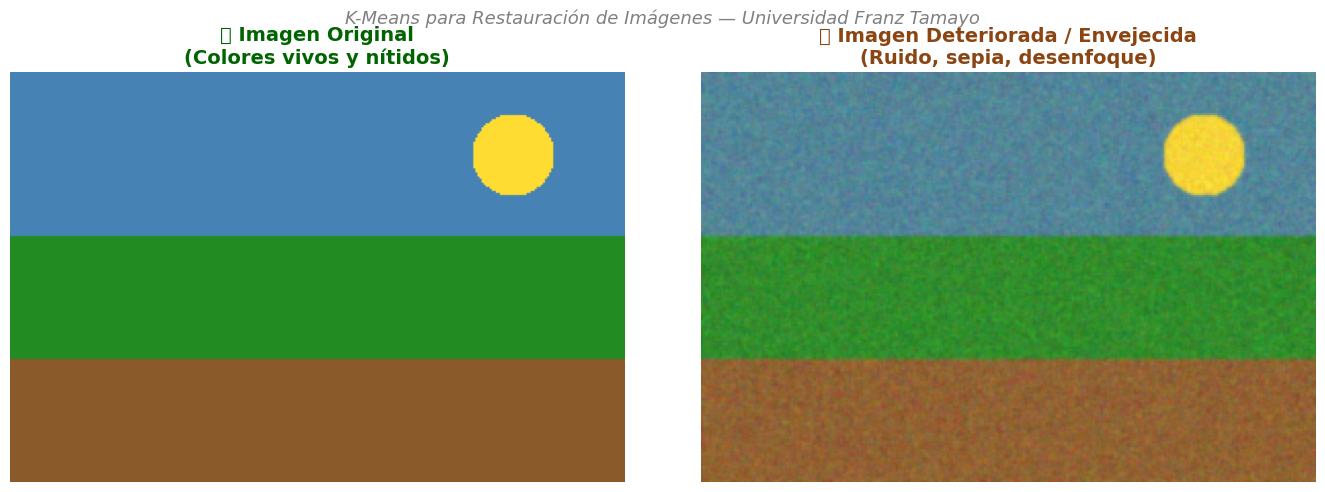


💡 Observa cómo el deterioro hace la imagen más amarillenta, ruidosa y sin contraste.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(img_original)
axes[0].set_title("📷 Imagen Original\n(Colores vivos y nítidos)",
                  fontsize=14, fontweight='bold', color='darkgreen')
axes[0].axis('off')

axes[1].imshow(img_deteriorada)
axes[1].set_title("🕰️ Imagen Deteriorada / Envejecida\n(Ruido, sepia, desenfoque)",
                  fontsize=14, fontweight='bold', color='saddlebrown')
axes[1].axis('off')

plt.suptitle("K-Means para Restauración de Imágenes — Universidad Franz Tamayo",
             fontsize=13, style='italic', color='gray')
plt.tight_layout()
plt.savefig('img_paso1_comparacion.png', dpi=120, bbox_inches='tight')
plt.show()
print("\n💡 Observa cómo el deterioro hace la imagen más amarillenta, ruidosa y sin contraste.")

---
## 🔬 Paso 4: Preparar los Datos para K-Means

Transformamos la imagen en una **matriz de píxeles** para que K-Means pueda procesarla.

```
Imagen (alto × ancho × 3)  →  Matriz (N_píxeles × 3)
   [200, 300, 3]           →     [60000, 3]
```

In [5]:
# ── Convertir imagen deteriorada a array numpy ───────────────
arr_deteriorada = np.array(img_deteriorada, dtype=np.float32)
arr_original    = np.array(img_original,    dtype=np.float32)

alto, ancho, canales = arr_deteriorada.shape
print(f"📐 Forma original de la imagen: {arr_deteriorada.shape}")
print(f"   Alto   : {alto} píxeles")
print(f"   Ancho  : {ancho} píxeles")
print(f"   Canales: {canales} (R, G, B)")
print()

# ── Aplanar la imagen → cada píxel es una fila ───────────────
# reshape(-1, 3): convierte (alto, ancho, 3) → (alto*ancho, 3)
pixeles = arr_deteriorada.reshape(-1, 3)
print(f"📊 Forma del dataset de píxeles: {pixeles.shape}")
print(f"   Cada fila = 1 píxel con [R, G, B]")
print(f"   Total de 'muestras' para K-Means: {pixeles.shape[0]:,}")
print()

# ── Normalizar a [0, 1] para mejor rendimiento de K-Means ────
pixeles_norm = pixeles / 255.0
print("✅ Datos preparados:")
print(f"   Rango de valores: [{pixeles_norm.min():.3f}, {pixeles_norm.max():.3f}]")
print(f"   Primeros 3 píxeles (R, G, B):")
for i, p in enumerate(pixeles_norm[:3]):
    print(f"   Píxel {i+1}: R={p[0]:.3f}  G={p[1]:.3f}  B={p[2]:.3f}")

📐 Forma original de la imagen: (200, 300, 3)
   Alto   : 200 píxeles
   Ancho  : 300 píxeles
   Canales: 3 (R, G, B)

📊 Forma del dataset de píxeles: (60000, 3)
   Cada fila = 1 píxel con [R, G, B]
   Total de 'muestras' para K-Means: 60,000

✅ Datos preparados:
   Rango de valores: [0.094, 1.000]
   Primeros 3 píxeles (R, G, B):
   Píxel 1: R=0.369  G=0.514  B=0.616
   Píxel 2: R=0.396  G=0.522  B=0.592
   Píxel 3: R=0.388  G=0.537  B=0.580


---
## 🔍 Paso 5: Método del Codo (Elbow Method) para Elegir K

Aplicamos el **Método del Codo** para encontrar el K óptimo en el espacio de colores.

> ⚠️ Para imágenes, usaremos K relativamente pequeños (2–32) ya que el objetivo
> es comprimir/simplificar la paleta de colores, no encontrar miles de grupos.

⏳ Calculando inercia para K = 2 ... 16  (esto puede tomar unos segundos)
   K= 2  |  WCSS = 104.8475
   K= 3  |  WCSS = 22.7869
   K= 4  |  WCSS = 5.9765
   K= 5  |  WCSS = 5.4902
   K= 6  |  WCSS = 5.0153
   K= 7  |  WCSS = 4.5649
   K= 8  |  WCSS = 4.2744
   K= 9  |  WCSS = 3.9611
   K=10  |  WCSS = 3.7484
   K=11  |  WCSS = 3.5607
   K=12  |  WCSS = 3.4368
   K=13  |  WCSS = 3.1861
   K=14  |  WCSS = 3.0320
   K=15  |  WCSS = 2.8873
   K=16  |  WCSS = 2.7662


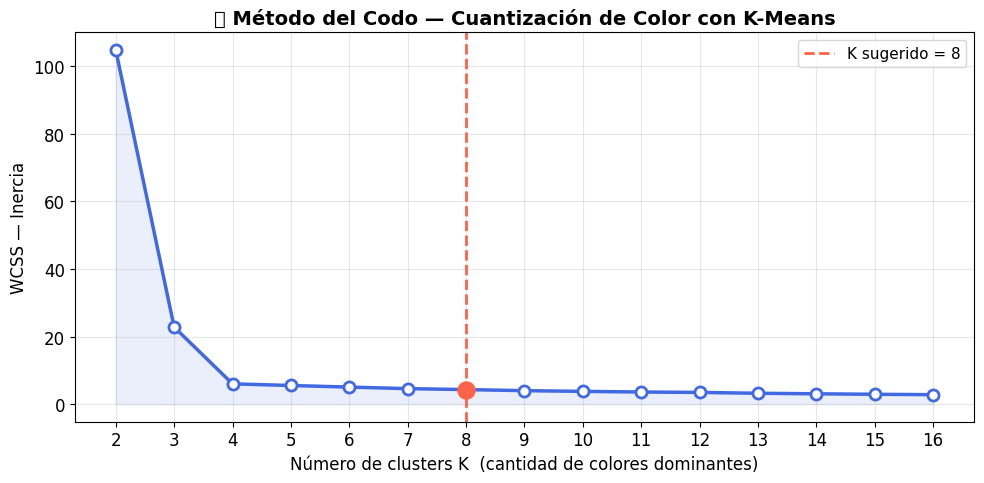


✅ El 'codo' sugiere K ≈ 8 colores dominantes para una buena restauración


In [7]:
# ── Método del Codo en espacio de color ─────────────────────
# Usamos una muestra de píxeles para acelerar el cálculo
N_MUESTRA = 3000   # muestreo representativo
np.random.seed(42)
idx_muestra = np.random.choice(len(pixeles_norm), N_MUESTRA, replace=False)
muestra = pixeles_norm[idx_muestra]

valores_k  = range(2, 17)
inercias   = []

print("⏳ Calculando inercia para K = 2 ... 16  (esto puede tomar unos segundos)")
for k in valores_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=5, max_iter=100)
    km.fit(muestra)
    inercias.append(km.inertia_)
    print(f"   K={k:2d}  |  WCSS = {km.inertia_:.4f}")

# ── Gráfico del Codo ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(list(valores_k), inercias, 'o-', color='royalblue',
        linewidth=2.5, markersize=8, markerfacecolor='white', markeredgewidth=2)
ax.fill_between(list(valores_k), inercias, alpha=0.1, color='royalblue')

# Marcar K óptimo sugerido
K_OPT = 8
ax.axvline(x=K_OPT, color='tomato', linestyle='--', linewidth=2,
           label=f'K sugerido = {K_OPT}')
ax.scatter([K_OPT], [inercias[K_OPT - 2]], color='tomato', s=150, zorder=5)

ax.set_xlabel('Número de clusters K  (cantidad de colores dominantes)', fontsize=12)
ax.set_ylabel('WCSS — Inercia', fontsize=12)
ax.set_title('📉 Método del Codo — Cuantización de Color con K-Means', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_xticks(list(valores_k))
plt.tight_layout()
plt.savefig('img_paso2_codo.png', dpi=120, bbox_inches='tight')
plt.show()

print(f"\n✅ El 'codo' sugiere K ≈ {K_OPT} colores dominantes para una buena restauración")

---
## 🤖 Paso 6: Aplicar K-Means y Reconstruir la Imagen

Ahora entrenamos K-Means con el **K elegido** y reconstruimos la imagen reemplazando
cada píxel por el color del centroide de su cluster.

In [8]:
def restaurar_con_kmeans(arr_img, k, random_state=42):
    """
    Aplica K-Means sobre los píxeles de una imagen y reconstruye
    la imagen usando solo los K colores dominantes (centroides).
    
    Parámetros:
    -----------
    arr_img      : np.ndarray  — imagen como array (alto, ancho, 3) en float32
    k            : int         — número de colores dominantes
    random_state : int         — semilla de aleatoriedad
    
    Retorna:
    --------
    img_restaurada : PIL.Image  — imagen reconstruida con K colores
    km             : KMeans     — modelo entrenado
    centroides     : np.ndarray — los K colores dominantes [0, 1]
    """
    alto, ancho, _ = arr_img.shape
    
    # 1️⃣  Aplanar y normalizar
    pixeles = arr_img.reshape(-1, 3) / 255.0
    
    # 2️⃣  Entrenar K-Means
    print(f"  ⚙️  Entrenando K-Means con K={k}...")
    km = KMeans(n_clusters=k, random_state=random_state, n_init=10, max_iter=300)
    etiquetas = km.fit_predict(pixeles)
    
    # 3️⃣  Reemplazar cada píxel por el color de su centroide
    centroides = km.cluster_centers_                    # shape (k, 3) en [0, 1]
    pixeles_restaurados = centroides[etiquetas]         # shape (N_pixeles, 3)
    
    # 4️⃣  Reconstruir la imagen
    arr_restaurado = (pixeles_restaurados.reshape(alto, ancho, 3) * 255).astype(np.uint8)
    img_restaurada = Image.fromarray(arr_restaurado)
    
    print(f"  ✅ Imagen reconstruida con {k} colores dominantes")
    return img_restaurada, km, centroides


# ── Aplicar restauración con K=8 ─────────────────────────────
print("🎨 Iniciando restauración de imagen...")
img_restaurada_8, km_8, centroides_8 = restaurar_con_kmeans(arr_deteriorada, k=8)

print()
print("📊 Los 8 colores dominantes encontrados (R, G, B):")
for i, c in enumerate(centroides_8):
    r, g, b = int(c[0]*255), int(c[1]*255), int(c[2]*255)
    print(f"   Color {i+1}: R={r:3d}  G={g:3d}  B={b:3d}")

🎨 Iniciando restauración de imagen...
  ⚙️  Entrenando K-Means con K=8...
  ✅ Imagen reconstruida con 8 colores dominantes

📊 Los 8 colores dominantes encontrados (R, G, B):
   Color 1: R=149  G= 95  B= 50
   Color 2: R= 82  G=127  B=153
   Color 3: R= 45  G=142  B= 43
   Color 4: R=242  G=211  B= 57
   Color 5: R= 76  G=136  B=150
   Color 6: R=140  G=101  B= 50
   Color 7: R= 56  G=139  B= 45
   Color 8: R= 89  G=137  B=151


---
## 📊 Paso 7: Comparación Triple — Original / Deteriorada / Restaurada

Visualizamos las tres versiones de la imagen para evaluar el resultado.

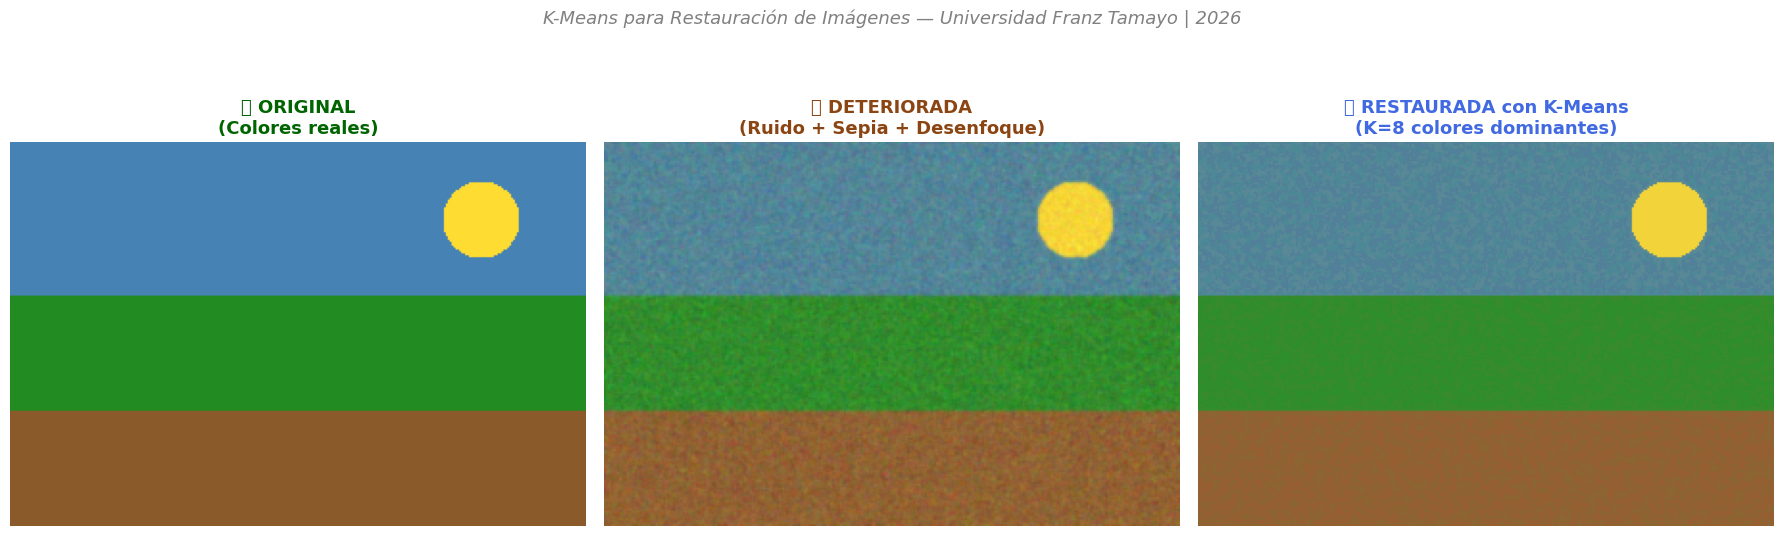


💡 K-Means elimina el ruido agrupando colores similares → imagen más limpia y con colores sólidos.


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Imagen 1: Original
axes[0].imshow(img_original)
axes[0].set_title("📷 ORIGINAL\n(Colores reales)",
                  fontsize=13, fontweight='bold', color='darkgreen')
axes[0].axis('off')

# Imagen 2: Deteriorada
axes[1].imshow(img_deteriorada)
axes[1].set_title("🕰️ DETERIORADA\n(Ruido + Sepia + Desenfoque)",
                  fontsize=13, fontweight='bold', color='saddlebrown')
axes[1].axis('off')

# Imagen 3: Restaurada con K-Means
axes[2].imshow(img_restaurada_8)
axes[2].set_title(f"🎨 RESTAURADA con K-Means\n(K=8 colores dominantes)",
                  fontsize=13, fontweight='bold', color='royalblue')
axes[2].axis('off')

plt.suptitle("K-Means para Restauración de Imágenes — Universidad Franz Tamayo | 2026",
             fontsize=13, style='italic', color='gray', y=1.01)
plt.tight_layout()
plt.savefig('img_paso3_comparacion_triple.png', dpi=130, bbox_inches='tight')
plt.show()
print("\n💡 K-Means elimina el ruido agrupando colores similares → imagen más limpia y con colores sólidos.")

---
## 🎨 Paso 8: Paleta de Colores Dominantes

Visualizamos los **K centroides** como una paleta de colores. Estos son los colores que
K-Means encontró como los más representativos de la imagen deteriorada.

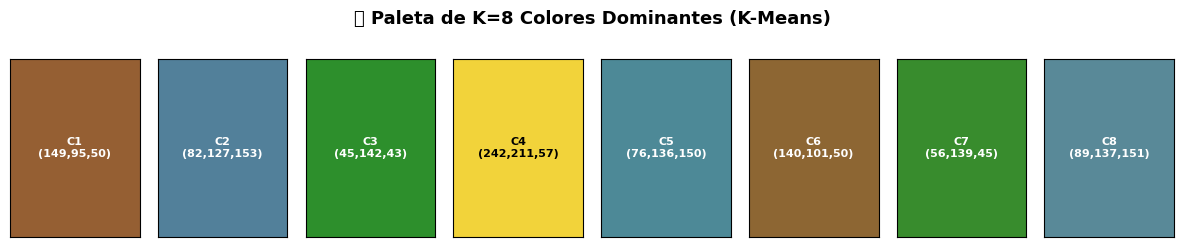

💡 Estos son los únicos colores usados en la imagen restaurada.
   K-Means los encontró de forma automática, sin intervención humana.


In [10]:
def mostrar_paleta(centroides, titulo="Paleta de Colores Dominantes"):
    """
    Muestra la paleta de colores encontrada por K-Means (los centroides).
    """
    k = len(centroides)
    fig, axes = plt.subplots(1, k, figsize=(k * 1.5, 2.5))
    
    for i, c in enumerate(centroides):
        color = np.clip(c, 0, 1)
        axes[i].add_patch(plt.Rectangle((0, 0), 1, 1,
                                         color=color, transform=axes[i].transAxes))
        r, g, b = int(c[0]*255), int(c[1]*255), int(c[2]*255)
        # Determinar si el texto debe ser blanco o negro según luminosidad
        luminosidad = 0.299*r + 0.587*g + 0.114*b
        color_texto = 'white' if luminosidad < 128 else 'black'
        axes[i].text(0.5, 0.5, f"C{i+1}\n({r},{g},{b})",
                     ha='center', va='center', fontsize=8,
                     color=color_texto, fontweight='bold',
                     transform=axes[i].transAxes)
        axes[i].set_xticks([])
        axes[i].set_yticks([])
    
    plt.suptitle(titulo, fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig('img_paso4_paleta.png', dpi=120, bbox_inches='tight')
    plt.show()


mostrar_paleta(centroides_8,
               titulo=f"🎨 Paleta de K={len(centroides_8)} Colores Dominantes (K-Means)")

print("💡 Estos son los únicos colores usados en la imagen restaurada.")
print("   K-Means los encontró de forma automática, sin intervención humana.")

---
## 🔬 Paso 9: Efecto de K — Comparación con Múltiples Valores

Exploramos cómo cambia la calidad de la imagen restaurada al variar K.

> ⏱️ Esta celda puede tardar 1–2 minutos. Cada K requiere un K-Means completo.

⏳ Generando restauraciones con distintos valores de K...
  ⚙️  Entrenando K-Means con K=2...
  ✅ Imagen reconstruida con 2 colores dominantes
  ⚙️  Entrenando K-Means con K=4...
  ✅ Imagen reconstruida con 4 colores dominantes
  ⚙️  Entrenando K-Means con K=8...
  ✅ Imagen reconstruida con 8 colores dominantes
  ⚙️  Entrenando K-Means con K=16...
  ✅ Imagen reconstruida con 16 colores dominantes
  ⚙️  Entrenando K-Means con K=32...
  ✅ Imagen reconstruida con 32 colores dominantes
  ⚙️  Entrenando K-Means con K=64...
  ✅ Imagen reconstruida con 64 colores dominantes

✅ Todas las restauraciones completadas.


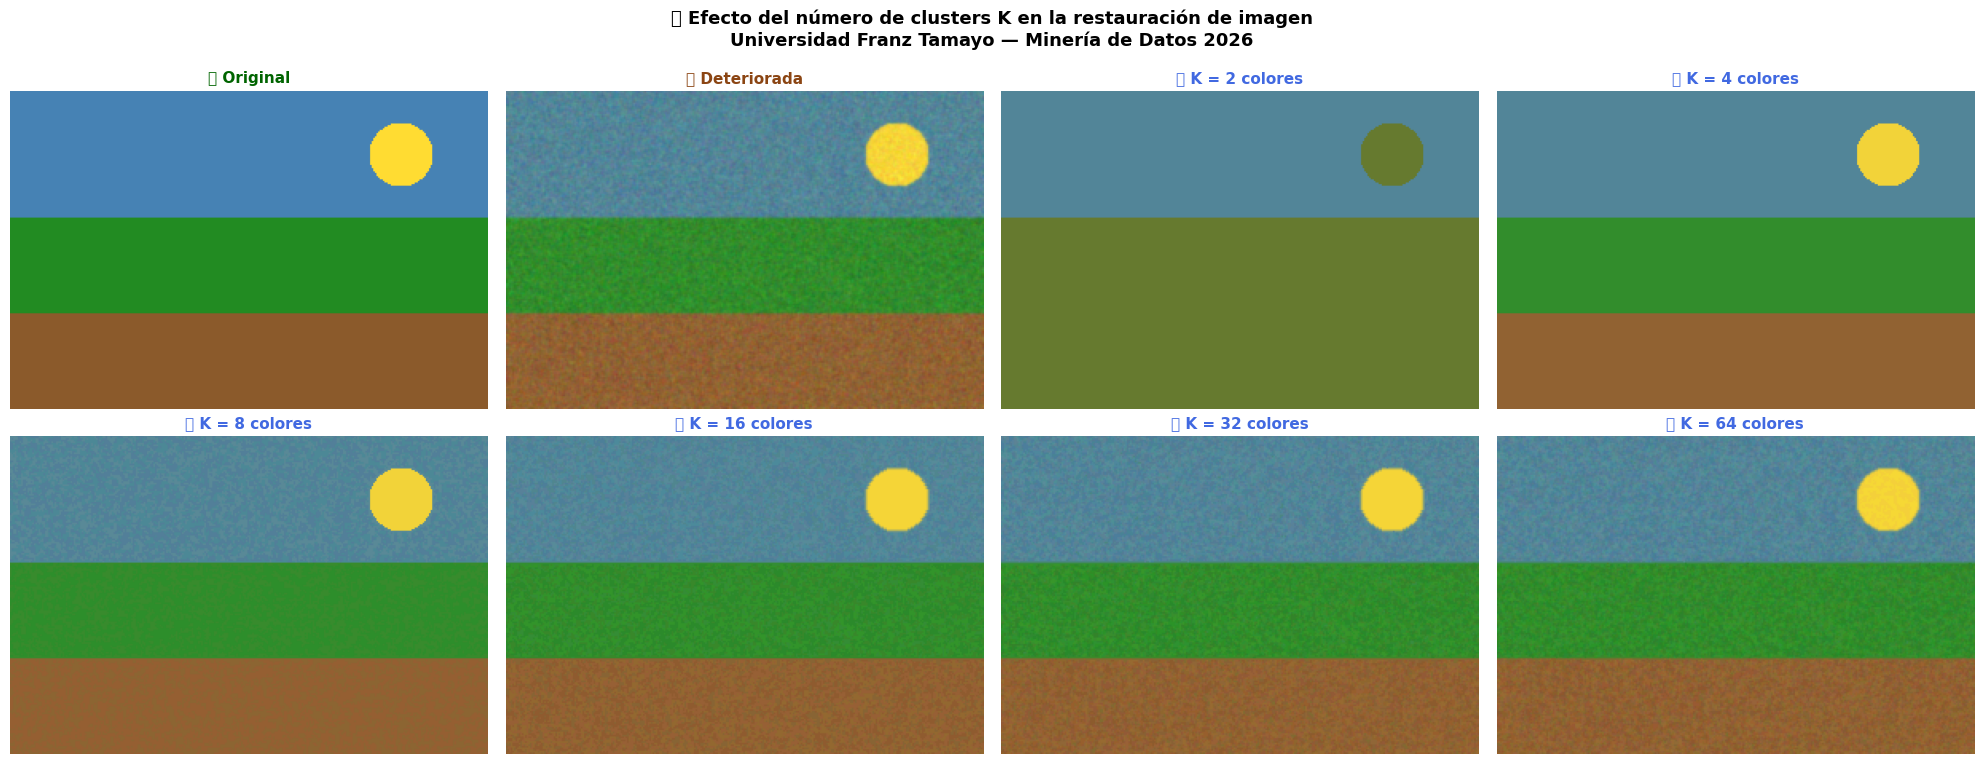


📌 Observaciones:
   K=2   → Solo 2 colores: imagen casi binaria (blanco/negro de color)
   K=4   → Efecto de arte abstracto o póster
   K=8   → Balance entre simplificación y detalle
   K=16  → Imagen reconocible con ruido eliminado
   K=32+ → Muy cercana al original pero más limpia


In [11]:
# ── Restaurar con diferentes valores de K ───────────────────
VALORES_K = [2, 4, 8, 16, 32, 64]
imagenes_restauradas = {}

print("⏳ Generando restauraciones con distintos valores de K...")
for k in VALORES_K:
    img_r, _, _ = restaurar_con_kmeans(arr_deteriorada, k=k)
    imagenes_restauradas[k] = img_r

print("\n✅ Todas las restauraciones completadas.")

# ── Visualización comparativa ─────────────────────────────────
n = len(VALORES_K)
fig, axes = plt.subplots(2, n // 2 + 1, figsize=(20, 8))
axes = axes.flatten()

# Original y deteriorada primero
axes[0].imshow(img_original)
axes[0].set_title("📷 Original", fontsize=11, fontweight='bold', color='darkgreen')
axes[0].axis('off')

axes[1].imshow(img_deteriorada)
axes[1].set_title("🕰️ Deteriorada", fontsize=11, fontweight='bold', color='saddlebrown')
axes[1].axis('off')

# Restauraciones con distintos K
for i, k in enumerate(VALORES_K):
    ax = axes[i + 2]
    ax.imshow(imagenes_restauradas[k])
    ax.set_title(f"🎨 K = {k} colores", fontsize=11, fontweight='bold', color='royalblue')
    ax.axis('off')

# Ocultar ejes sobrantes si los hay
for j in range(n + 2, len(axes)):
    axes[j].axis('off')

plt.suptitle("🔬 Efecto del número de clusters K en la restauración de imagen\n"
             "Universidad Franz Tamayo — Minería de Datos 2026",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('img_paso5_efecto_k.png', dpi=120, bbox_inches='tight')
plt.show()

print("\n📌 Observaciones:")
print("   K=2   → Solo 2 colores: imagen casi binaria (blanco/negro de color)")
print("   K=4   → Efecto de arte abstracto o póster")
print("   K=8   → Balance entre simplificación y detalle")
print("   K=16  → Imagen reconocible con ruido eliminado")
print("   K=32+ → Muy cercana al original pero más limpia")

---
## 📊 Paso 10: Análisis de Histogramas de Color — Antes vs. Después

El **histograma de color** muestra la distribución de valores R, G, B en la imagen.
Comparar los histogramas nos permite cuantificar el cambio en la distribución de colores.

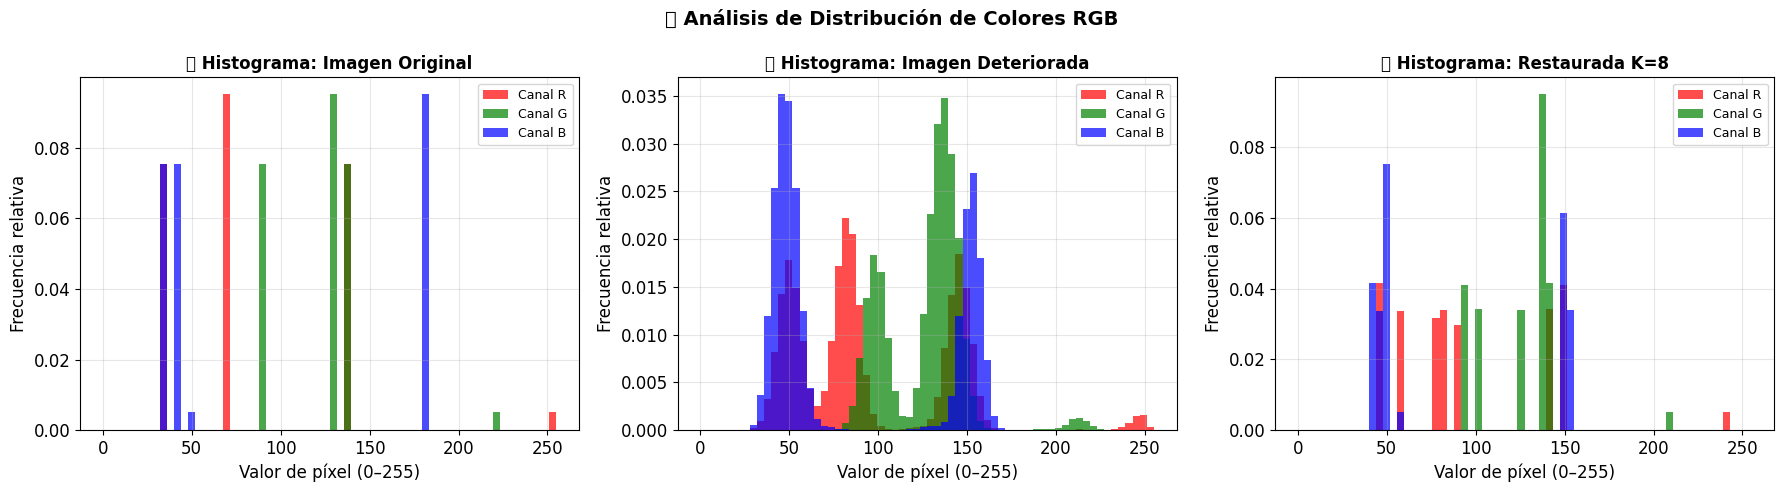

💡 Interpretación de histogramas:
   Original  → Distribución amplia y equilibrada en los 3 canales
   Deteriorada → Canal R elevado (tinte sepia), canales desplazados por ruido
   Restaurada → Solo K picos discretos (uno por centroide)


In [12]:
def histograma_rgb(ax, img_arr, titulo, alpha=0.7):
    """Dibuja el histograma RGB de una imagen en un eje dado."""
    colores_rgb = ['red', 'green', 'blue']
    nombres = ['Canal R', 'Canal G', 'Canal B']
    for i, (color, nombre) in enumerate(zip(colores_rgb, nombres)):
        canal = img_arr[:, :, i].flatten()
        ax.hist(canal, bins=64, range=(0, 255), color=color,
                alpha=alpha, label=nombre, density=True)
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_xlabel('Valor de píxel (0–255)')
    ax.set_ylabel('Frecuencia relativa')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

histograma_rgb(axes[0], arr_original,
               "📷 Histograma: Imagen Original")
histograma_rgb(axes[1], np.array(img_deteriorada),
               "🕰️ Histograma: Imagen Deteriorada")
histograma_rgb(axes[2], np.array(img_restaurada_8),
               "🎨 Histograma: Restaurada K=8")

plt.suptitle("📊 Análisis de Distribución de Colores RGB",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('img_paso6_histogramas.png', dpi=120, bbox_inches='tight')
plt.show()

print("💡 Interpretación de histogramas:")
print("   Original  → Distribución amplia y equilibrada en los 3 canales")
print("   Deteriorada → Canal R elevado (tinte sepia), canales desplazados por ruido")
print("   Restaurada → Solo K picos discretos (uno por centroide)")

---
## 📏 Paso 11: Métricas de Calidad de Restauración

Evaluamos cuantitativamente qué tan bien K-Means restauró la imagen comparada con la original.

| Métrica | Descripción | Ideal |
|---|---|---|
| **MSE** | Error cuadrático medio entre píxeles | Menor → mejor |
| **PSNR** | Relación señal-ruido (dB) | Mayor → mejor |
| **Reducción de ruido** | % de reducción de error vs. deteriorada | Mayor → mejor |

📊 MÉTRICAS DE CALIDAD
                                         MSE   PSNR (dB)
-------------------------------------------------------
  Imagen Deteriorada vs. Original       220.58       24.70
-------------------------------------------------------
  Restaurada K=  2 vs. Original        1095.95       17.73  (-396.9% error)
  Restaurada K=  4 vs. Original         171.42       25.79  (+22.3% error)
  Restaurada K=  8 vs. Original         187.86       25.39  (+14.8% error)
  Restaurada K= 16 vs. Original         195.60       25.22  (+11.3% error)
  Restaurada K= 32 vs. Original         204.09       25.03  (+7.5% error)
  Restaurada K= 64 vs. Original         208.70       24.94  (+5.4% error)



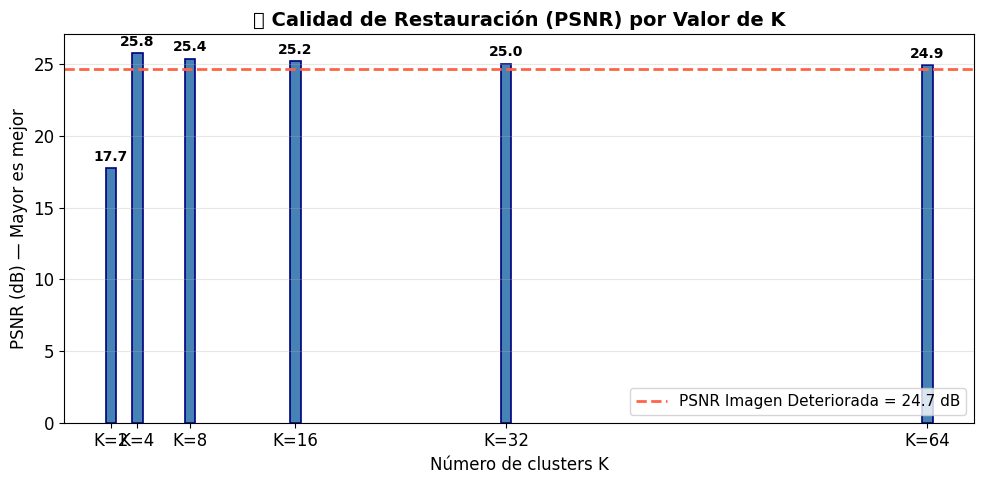

🏆 Mejor restauración: K=4  →  PSNR=25.79 dB


In [13]:
def calcular_mse(img1_arr, img2_arr):
    """Calcula el Error Cuadrático Medio entre dos imágenes."""
    return np.mean((img1_arr.astype(float) - img2_arr.astype(float)) ** 2)

def calcular_psnr(mse, max_val=255.0):
    """Calcula el PSNR (Peak Signal-to-Noise Ratio) en dB."""
    if mse == 0:
        return float('inf')
    return 20 * np.log10(max_val / np.sqrt(mse))


# ── Calcular métricas ─────────────────────────────────────────
arr_det = np.array(img_deteriorada).astype(float)

mse_deteriorada  = calcular_mse(arr_original, arr_det)
psnr_deteriorada = calcular_psnr(mse_deteriorada)

print("📊 MÉTRICAS DE CALIDAD")
print("=" * 55)
print(f"{'':35} {'MSE':>8}  {'PSNR (dB)':>10}")
print("-" * 55)
print(f"  Imagen Deteriorada vs. Original     {mse_deteriorada:8.2f}  {psnr_deteriorada:10.2f}")
print("-" * 55)

resultados = []
for k in VALORES_K:
    arr_rest = np.array(imagenes_restauradas[k]).astype(float)
    mse_rest  = calcular_mse(arr_original, arr_rest)
    psnr_rest = calcular_psnr(mse_rest)
    reduccion = (1 - mse_rest / mse_deteriorada) * 100
    resultados.append((k, mse_rest, psnr_rest, reduccion))
    print(f"  Restaurada K={k:3d} vs. Original       {mse_rest:8.2f}  {psnr_rest:10.2f}  ({reduccion:+.1f}% error)")

print("=" * 55)
print()

# ── Gráfico comparativo de PSNR ───────────────────────────────
ks     = [r[0] for r in resultados]
psnrs  = [r[2] for r in resultados]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(ks, psnrs, color='steelblue', edgecolor='navy', linewidth=1.2)
ax.axhline(psnr_deteriorada, color='tomato', linestyle='--', linewidth=2,
           label=f'PSNR Imagen Deteriorada = {psnr_deteriorada:.1f} dB')

for bar, psnr in zip(bars, psnrs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{psnr:.1f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xlabel('Número de clusters K', fontsize=12)
ax.set_ylabel('PSNR (dB) — Mayor es mejor', fontsize=12)
ax.set_title('📏 Calidad de Restauración (PSNR) por Valor de K', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, axis='y', alpha=0.3)
ax.set_xticks(ks)
ax.set_xticklabels([f'K={k}' for k in ks])
plt.tight_layout()
plt.savefig('img_paso7_psnr.png', dpi=120, bbox_inches='tight')
plt.show()

mejor = max(resultados, key=lambda x: x[2])
print(f"🏆 Mejor restauración: K={mejor[0]}  →  PSNR={mejor[2]:.2f} dB")

---
## 💾 Paso 12: Guardar las Imágenes Resultantes

Guardamos todas las imágenes generadas para referencia futura.

In [ ]:
import os

# ── Crear carpeta de resultados ──────────────────────────────
os.makedirs('resultados_kmeans_imagen', exist_ok=True)

# ── Guardar imágenes ─────────────────────────────────────────
img_original.save('resultados_kmeans_imagen/01_original.png')
img_deteriorada.save('resultados_kmeans_imagen/02_deteriorada.png')

for k, img_r in imagenes_restauradas.items():
    img_r.save(f'resultados_kmeans_imagen/03_restaurada_k{k:03d}.png')

print("✅ Imágenes guardadas en: resultados_kmeans_imagen/")
print()
archivos = sorted(os.listdir('resultados_kmeans_imagen'))
for f in archivos:
    ruta = os.path.join('resultados_kmeans_imagen', f)
    tam  = os.path.getsize(ruta) / 1024
    print(f"   📁 {f:40s} ({tam:.1f} KB)")

print()
print("💡 Puedes abrir la carpeta 'resultados_kmeans_imagen' para ver los archivos.")

---
# 🧠 ACTIVIDAD PARTICIPATIVA 2: Experimentación

---

## 🧠 ACTIVIDAD 2: Experimenta con tus propios parámetros

> 📝 **Instrucciones**: Modifica los valores sugeridos en la celda de código siguiente y
> observa cómo cambia el resultado. Responde las preguntas al final.

**Cosas para explorar:**
- Cambiar `INTENSIDAD_DETERIORO` (0.1 = leve, 0.9 = extremo)
- Cambiar `K_RESTAURACION` (2 = muy abstracto, 64 = muy detallado)
- Probar con una imagen diferente cambiando `URL_IMAGEN_CUSTOM`

ℹ️  Usando imagen original (URL_IMAGEN_CUSTOM = None)
  ⚙️  Entrenando K-Means con K=12...
  ✅ Imagen reconstruida con 12 colores dominantes


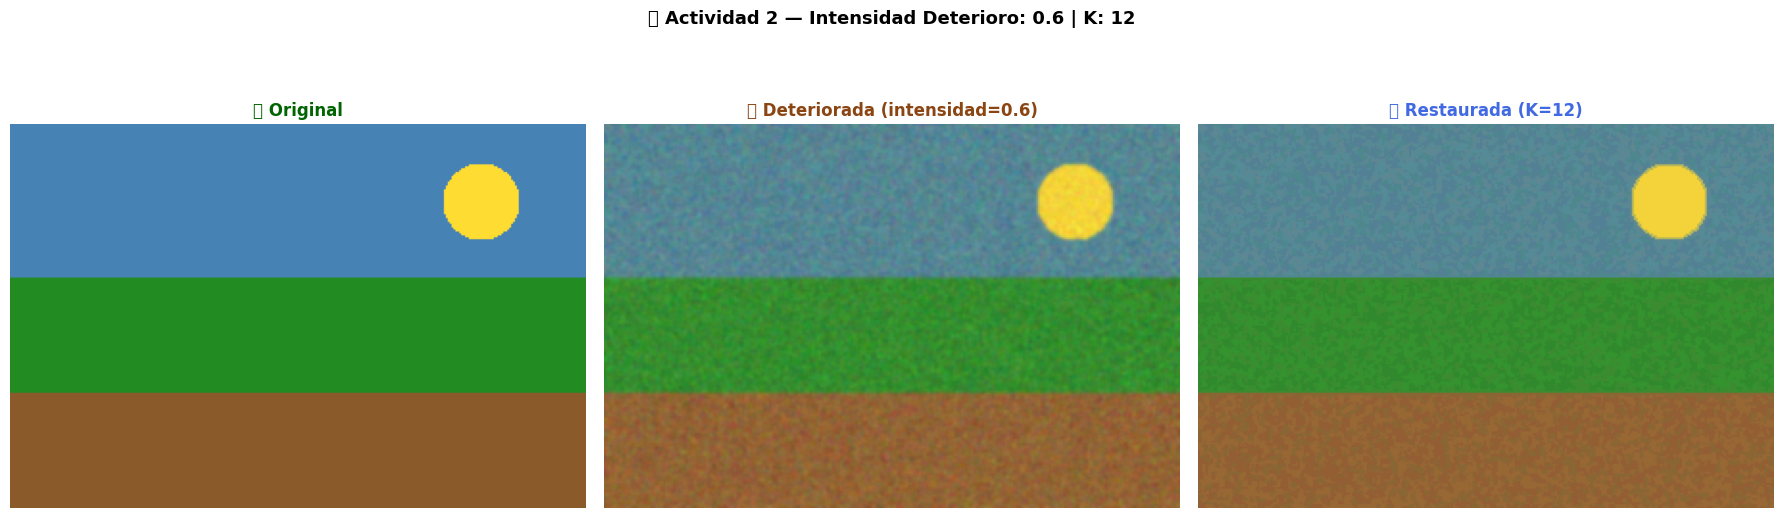

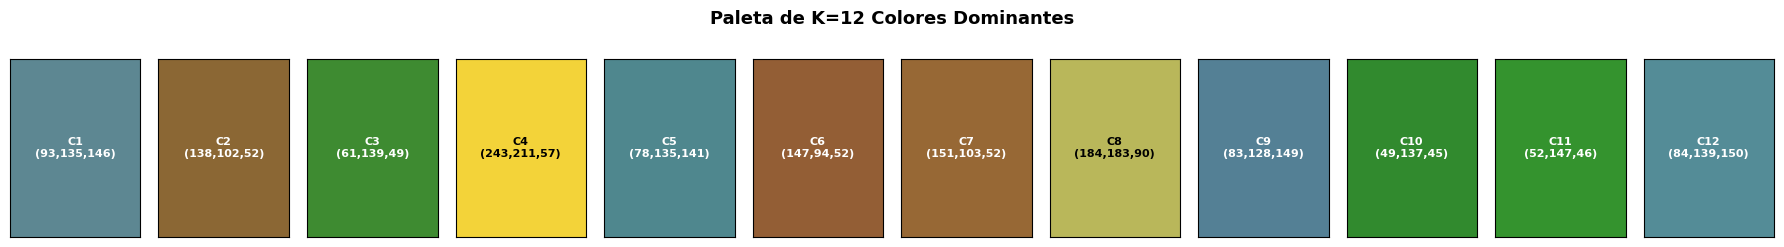

In [14]:
# ─────────────────────────────────────────────────────────────
# ✏️  MODIFICA ESTOS PARÁMETROS Y OBSERVA LOS CAMBIOS
# ─────────────────────────────────────────────────────────────

INTENSIDAD_DETERIORO = 0.6   # Entre 0.1 (suave) y 0.9 (extremo)
K_RESTAURACION       = 12    # Número de colores dominantes

# Puedes cambiar esta URL por otra imagen pública
URL_IMAGEN_CUSTOM = None     # Pon una URL aquí, o deja None para usar la original

# ─────────────────────────────────────────────────────────────

# Cargar imagen personalizada si se proporcionó URL
if URL_IMAGEN_CUSTOM:
    try:
        resp = requests.get(URL_IMAGEN_CUSTOM, timeout=15)
        img_custom = Image.open(BytesIO(resp.content)).convert("RGB")
        img_custom = img_custom.resize((300, 200), Image.LANCZOS)
        print(f"✅ Imagen personalizada cargada desde URL")
    except Exception as e:
        print(f"⚠️  Error al cargar URL: {e}. Usando imagen original.")
        img_custom = img_original
else:
    img_custom = img_original
    print("ℹ️  Usando imagen original (URL_IMAGEN_CUSTOM = None)")

# Aplicar deterioro y restauración con los parámetros elegidos
img_det_custom  = deteriorar_imagen(img_custom, intensidad=INTENSIDAD_DETERIORO)
arr_det_custom  = np.array(img_det_custom, dtype=np.float32)
img_rest_custom, km_custom, centroides_custom = restaurar_con_kmeans(
    arr_det_custom, k=K_RESTAURACION
)

# Visualización
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, img, titulo, color in zip(
    axes,
    [img_custom, img_det_custom, img_rest_custom],
    ["📷 Original", f"🕰️ Deteriorada (intensidad={INTENSIDAD_DETERIORO})",
     f"🎨 Restaurada (K={K_RESTAURACION})"],
    ['darkgreen', 'saddlebrown', 'royalblue']
):
    ax.imshow(img)
    ax.set_title(titulo, fontsize=12, fontweight='bold', color=color)
    ax.axis('off')

plt.suptitle(f"🧠 Actividad 2 — Intensidad Deterioro: {INTENSIDAD_DETERIORO} | K: {K_RESTAURACION}",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('img_actividad2_experimento.png', dpi=120, bbox_inches='tight')
plt.show()

# Paleta de colores
mostrar_paleta(centroides_custom,
               f"Paleta de K={K_RESTAURACION} Colores Dominantes")

### 📝 Preguntas de Reflexión (Actividad 2)

---

**1.** Al aumentar `INTENSIDAD_DETERIORO`, ¿qué cambios notaste en la imagen deteriorada? ¿Fue más difícil restaurarla?

> **✏️ Tu respuesta**: _____

---

**2.** Al cambiar `K_RESTAURACION`, ¿cuándo la imagen restaurada se parece más a la original? ¿Cuándo se aleja?

> **✏️ Tu respuesta**: _____

---

**3.** ¿Existe un K donde la restauración ya no mejora significativamente? ¿Cómo lo identificarías?

> **✏️ Tu respuesta**: _____

---

---
# 📋 PARTE 3: Resumen y Conclusiones
---

## 🏆 Resumen del Pipeline Implementado

```
📷 Imagen original  →  🕰️ Simular deterioro  →  🔢 Aplanar a (N_px, 3)
                                                         │
                                                    K-Means fit
                                                         │
                                          K centroides = K colores dominantes
                                                         │
                                         Reemplazar píxeles por centroides
                                                         │
                                               🎨 Imagen restaurada
```

## 🔑 Conceptos Clave Aprendidos

| Concepto | Explicación |
|---|---|
| **Cuantización de color** | Reducir millones de colores a K colores representativos |
| **Espacio RGB como dataset** | Cada píxel = punto 3D → listo para K-Means |
| **Centroide = color promedio** | El color representativo de un grupo de píxeles similares |
| **K pequeño** | Efecto artístico, muy abstracto |
| **K grande** | Mayor fidelidad al original, ruido eliminado |
| **PSNR** | Métrica cuantitativa de calidad de restauración |
| **Método del Codo** | Herramienta para elegir K óptimo |

## 🌟 Conexión con el Mundo Real

- 🏛️ **Museos**: restauración digital de obras de arte dañadas
- 📡 **Compresión**: formato GIF usa cuantización de color similar a K-Means
- 🛸 **Teledetección**: segmentación de imágenes satelitales por tipo de terreno
- 🏥 **Medicina**: segmentación de tejidos en imágenes de diagnóstico
- 🎨 **Arte digital**: efectos de póster y estilización artística automática

---

> 💡 **Reflexión final**: K-Means es un algoritmo simple pero extraordinariamente versátil.
> La misma lógica que segmenta clientes de iFood también puede restaurar imágenes deterioradas.
> ¡La diferencia está solo en los datos de entrada!

In [15]:
# ── Resumen final en consola ──────────────────────────────────
print("=" * 60)
print("  🎓 RESUMEN — K-Means para Restauración de Imágenes")
print("  Universidad Franz Tamayo | Minería de Datos | 2026")
print("=" * 60)
print()
print("  📷 Imagen de trabajo:")
print(f"     Dimensiones : {ancho} x {alto} px")
print(f"     Total píxeles: {ancho*alto:,}")
print()
print("  🕰️ Deterioro simulado:")
print("     • Ruido gaussiano")
print("     • Tinte sepia/amarillento")
print("     • Reducción de contraste")
print("     • Desenfoque gaussiano")
print()
print("  🎨 Restauraciones probadas:")
for k, mse, psnr, reduccion in resultados:
    estrella = " ⭐" if k == mejor[0] else ""
    print(f"     K={k:3d} → PSNR={psnr:.1f} dB  |  Error reducido en {reduccion:+.1f}%{estrella}")
print()
print(f"  🏆 Mejor K probado: K={mejor[0]} con PSNR={mejor[2]:.2f} dB")
print()
print("  ✅ Archivos guardados en: resultados_kmeans_imagen/")
print("=" * 60)

  🎓 RESUMEN — K-Means para Restauración de Imágenes
  Universidad Franz Tamayo | Minería de Datos | 2026

  📷 Imagen de trabajo:
     Dimensiones : 300 x 200 px
     Total píxeles: 60,000

  🕰️ Deterioro simulado:
     • Ruido gaussiano
     • Tinte sepia/amarillento
     • Reducción de contraste
     • Desenfoque gaussiano

  🎨 Restauraciones probadas:
     K=  2 → PSNR=17.7 dB  |  Error reducido en -396.9%
     K=  4 → PSNR=25.8 dB  |  Error reducido en +22.3% ⭐
     K=  8 → PSNR=25.4 dB  |  Error reducido en +14.8%
     K= 16 → PSNR=25.2 dB  |  Error reducido en +11.3%
     K= 32 → PSNR=25.0 dB  |  Error reducido en +7.5%
     K= 64 → PSNR=24.9 dB  |  Error reducido en +5.4%

  🏆 Mejor K probado: K=4 con PSNR=25.79 dB

  ✅ Archivos guardados en: resultados_kmeans_imagen/
